<a href="https://colab.research.google.com/github/byAnree/PIA_IAM/blob/main/PIA_IAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Final — Clasificación de Gestos (Piedra, Papel o Tijera) con CNN
CNN construida desde cero con TensorFlow/Keras sobre el dataset
[Rock, Paper, Scissors](https://www.kaggle.com/datasets/drgfreeman/rockpaperscissors).

**Antes de correr:** `Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)`

## Sección 1: Descarga, carga y preprocesamiento

In [1]:
import os, shutil, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# ─── Configuración e hiperparámetros ──────────────────────────────────────────
IMG_SIZE    = 128          # resolución uniforme (las imágenes originales son 300x200)
BATCH_SIZE  = 32
EPOCHS      = 25           # número fijo de épocas
SEED        = 42
CLASSES     = ['paper', 'rock', 'scissors']   # orden alfabético = orden de las etiquetas
NUM_CLASSES = len(CLASSES)
SPLIT_DIR   = '/content/rps_split'

random.seed(SEED); np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU disponible:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.1 Descarga del dataset desde Kaggle

In [2]:
import kagglehub

path = kagglehub.dataset_download('drgfreeman/rockpaperscissors')

def find_root(base):
    """Devuelve la carpeta (la menos profunda) que contiene paper/rock/scissors.
    El dataset trae una copia duplicada de las imágenes (rps-cv-images); al usar
    solo UNA raíz evitamos imágenes repetidas entre train/val/test (data leakage)."""
    for dirpath, dirnames, _ in os.walk(base):
        if set(CLASSES).issubset(dirnames):
            return dirpath
    raise FileNotFoundError('No se encontraron las carpetas paper/rock/scissors')

RAW_DIR = find_root(path)
print('Raíz del dataset:', RAW_DIR)
for c in CLASSES:
    print(f'  {c}: {len(os.listdir(os.path.join(RAW_DIR, c)))} imágenes')

Using Colab cache for faster access to the 'rockpaperscissors' dataset.
Raíz del dataset: /kaggle/input/rockpaperscissors
  paper: 712 imágenes
  rock: 726 imágenes
  scissors: 750 imágenes


### 1.2 División train / validation / test (70 / 15 / 15, estratificada)

In [3]:
paths, labels = [], []
for c in CLASSES:
    for f in sorted(os.listdir(os.path.join(RAW_DIR, c))):
        if f.lower().endswith(('.png', '.jpg', '.jpeg')):
            paths.append(os.path.join(RAW_DIR, c, f)); labels.append(c)

p_train, p_tmp, l_train, l_tmp = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_test, l_val, l_test = train_test_split(
    p_tmp, l_tmp, test_size=0.50, stratify=l_tmp, random_state=SEED)

if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)
for split, (ps, ls) in {'train': (p_train, l_train),
                        'val':   (p_val,   l_val),
                        'test':  (p_test,  l_test)}.items():
    for c in CLASSES:
        os.makedirs(f'{SPLIT_DIR}/{split}/{c}', exist_ok=True)
    for p, l in zip(ps, ls):
        shutil.copy(p, f'{SPLIT_DIR}/{split}/{l}/{os.path.basename(p)}')
    print(f'{split:5s}: {len(ps)} imágenes')

train: 1531 imágenes
val  : 328 imágenes
test : 329 imágenes


### 1.3 Redimensionado y normalización (÷255) + aumento de datos solo en train

Found 1531 files belonging to 3 classes.
Found 328 files belonging to 3 classes.
Found 329 files belonging to 3 classes.


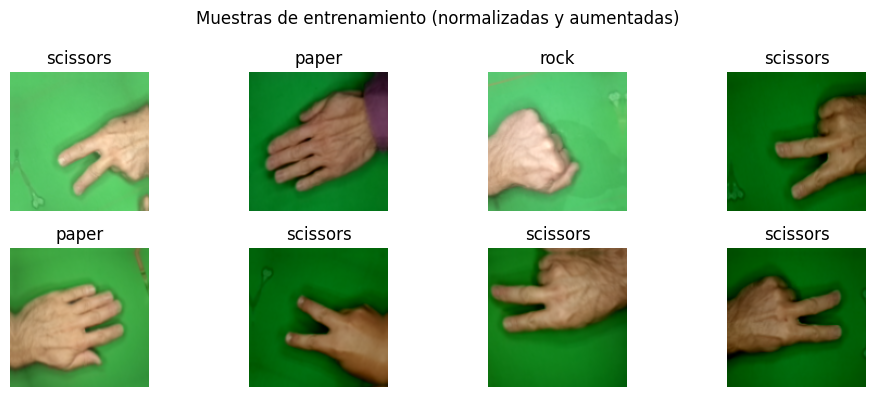

Rango de píxeles: 0.0 - 1.0


In [4]:
AUTOTUNE = tf.data.AUTOTUNE

def load_ds(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        f'{SPLIT_DIR}/{split}',
        labels='inferred', label_mode='categorical', class_names=CLASSES,
        color_mode='rgb', image_size=(IMG_SIZE, IMG_SIZE),   # redimensionado uniforme
        batch_size=BATCH_SIZE, shuffle=shuffle, seed=SEED)

train_raw = load_ds('train', True)
val_raw   = load_ds('val',   False)
test_raw  = load_ds('test',  False)   # shuffle=False: el orden de las predicciones coincide con las etiquetas

def normalize(x, y):
    return tf.cast(x, tf.float32) / 255.0, y      # píxeles a escala [0, 1]

# Aumento de datos: solo en entrenamiento. Sin flip vertical (una mano rara vez aparece boca abajo).
augment = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomBrightness(0.2, value_range=(0, 1)),
])

train_ds = (train_raw.map(normalize, num_parallel_calls=AUTOTUNE)
                     .map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
                     .prefetch(AUTOTUNE))
val_ds  = val_raw.map(normalize,  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_raw.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Vista rápida (con augmentation) para verificar el pipeline
x_b, y_b = next(iter(train_ds))
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x_b[i]); plt.axis('off')
    plt.title(CLASSES[int(tf.argmax(y_b[i]))])
plt.suptitle('Muestras de entrenamiento (normalizadas y aumentadas)')
plt.tight_layout(); plt.show()
print('Rango de píxeles:', float(tf.reduce_min(x_b)), '-', float(tf.reduce_max(x_b)))

**Pregunta 1.4 — ¿Por qué normalizar los píxeles antes de alimentar la CNN?**

Los píxeles crudos están en [0, 255]. Con esa escala, las salidas de las convoluciones (suma ponderada de muchos valores grandes) producen pre-activaciones enormes, lo que lleva a gradientes grandes e inestables: la pérdida oscila o se dispara, y el optimizador necesita una tasa de aprendizaje muy pequeña para no divergir. Los pesos se inicializan (Glorot/He) suponiendo entradas de magnitud cercana a 1, así que entradas de hasta 255 rompen ese supuesto. Llevar los valores a [0, 1] mantiene todas las entradas en la misma escala pequeña, estabiliza el cálculo de gradientes, evita la saturación de las activaciones y acelera la convergencia del entrenamiento con Adam o SGD.

## Sección 2: Diseño de la arquitectura CNN desde cero

In [5]:
def conv_block(filters, dropout):
    return [
        layers.Conv2D(filters, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(filters, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Dropout(dropout),
    ]

def build_model():
    model = models.Sequential(
        [layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))]
        + conv_block(32, 0.25)
        + conv_block(64, 0.25)
        + conv_block(128, 0.25)
        + conv_block(128, 0.25)
        + [
            layers.Flatten(),
            layers.Dense(256, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.5),
            layers.Dense(NUM_CLASSES, activation='softmax'),
        ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy'])
    return model

model = build_model()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,684,195 (10.24 MB)

 Trainable params: 2,682,275 (10.23 MB)

 Non-trainable params: 1,920 (7.50 KB)

## Sección 3: Entrenamiento, curvas de aprendizaje y evaluación en test

In [6]:
# Épocas fijas (sin EarlyStopping). ReduceLROnPlateau solo ajusta la tasa de aprendizaje.
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3,
                                         min_lr=1e-6, verbose=1)
]

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks)

Epoch 1/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 79s 968ms/step - accuracy: 0.6068 - loss: 1.1871 - val_accuracy: 0.3323 - val_loss: 2.0447 - learning_rate: 0.0010
Epoch 2/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 177ms/step - accuracy: 0.8504 - loss: 0.4557 - val_accuracy: 0.3323 - val_loss: 3.0262 - learning_rate: 0.0010
Epoch 3/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 177ms/step - accuracy: 0.9027 - loss: 0.2824 - val_accuracy: 0.3323 - val_loss: 4.7271 - learning_rate: 0.0010
Epoch 4/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.9472 - loss: 0.1478
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 199ms/step - accuracy: 0.9510 - loss: 0.1379 - val_accuracy: 0.3323 - val_loss: 8.9802 - learning_rate: 0.0010
Epoch 5/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 206ms/step - accuracy: 0.9621 - loss: 0.1177 - val_accuracy: 0.3323 - val_loss: 7.4088 - learning_rate: 5.0000e-04
Epoch 6/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 172ms/step - accuracy: 0.9726 - loss: 0.

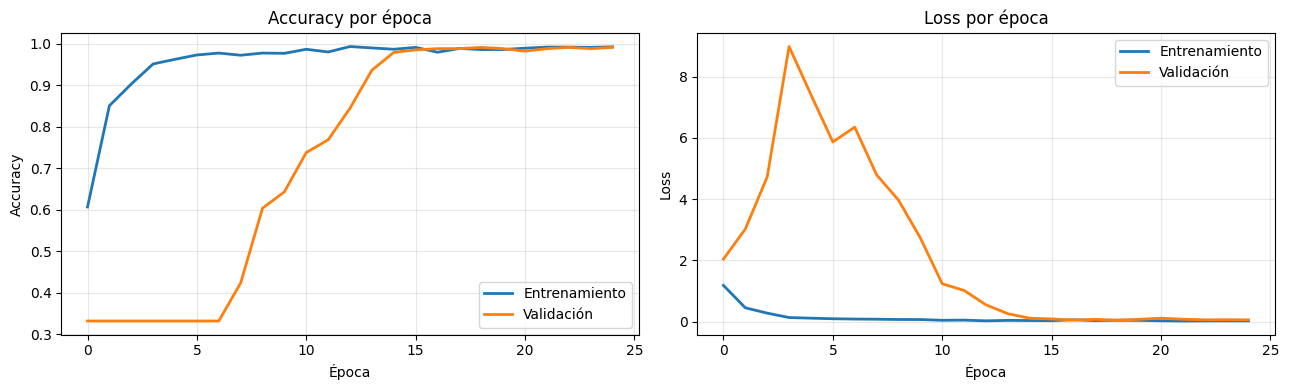

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(history.history['accuracy'],     label='Entrenamiento', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validación',    linewidth=2)
ax1.set_title('Accuracy por época'); ax1.set_xlabel('Época'); ax1.set_ylabel('Accuracy')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(history.history['loss'],     label='Entrenamiento', linewidth=2)
ax2.plot(history.history['val_loss'], label='Validación',    linewidth=2)
ax2.set_title('Loss por época'); ax2.set_xlabel('Época'); ax2.set_ylabel('Loss')
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('curvas_entrenamiento.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
test_loss, test_acc = model.evaluate(test_ds)
print(f'\nTest loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}')

11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 616ms/step - accuracy: 0.9939 - loss: 0.0227

Test loss: 0.0227 | Test accuracy: 0.9939


## Sección 4: Matriz de confusión, reporte de clasificación y análisis

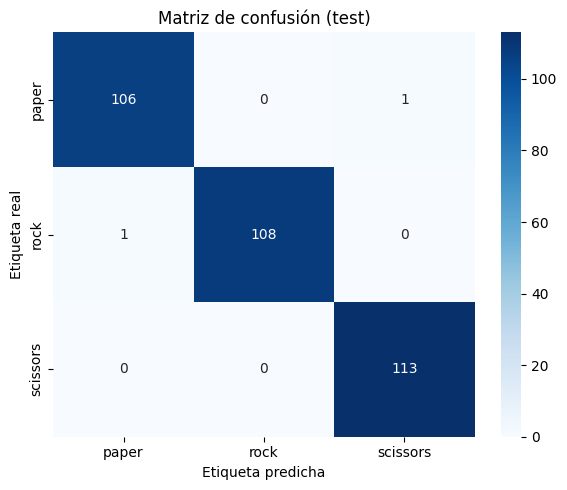

              precision    recall  f1-score   support

       paper     0.9907    0.9907    0.9907       107
        rock     1.0000    0.9908    0.9954       109
    scissors     0.9912    1.0000    0.9956       113

    accuracy                         0.9939       329
   macro avg     0.9940    0.9938    0.9939       329
weighted avg     0.9939    0.9939    0.9939       329



In [9]:
# test_ds no está barajado, así que el orden de y_true coincide con el de las predicciones
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])
x_test = np.concatenate([x.numpy() for x, _ in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Matriz de confusión (test)')
plt.ylabel('Etiqueta real'); plt.xlabel('Etiqueta predicha')
plt.tight_layout()
plt.savefig('matriz_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

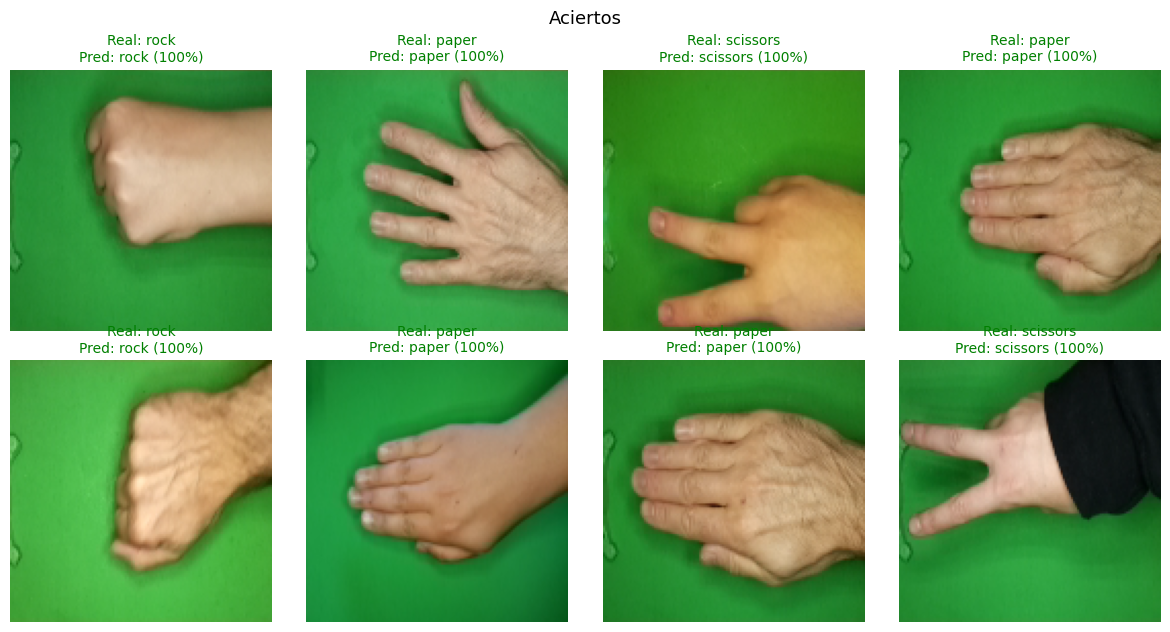

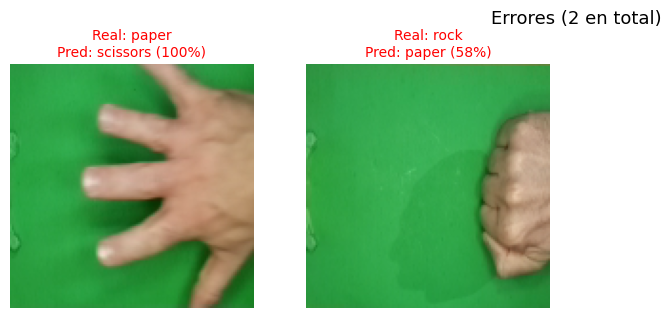

In [10]:
def show_examples(idx, title, n=8):
    idx = idx[:n]
    if len(idx) == 0:
        print(f'{title}: no hay ejemplos'); return
    cols = 4
    rows = int(np.ceil(len(idx) / cols))
    plt.figure(figsize=(3 * cols, 3.2 * rows))
    for k, i in enumerate(idx):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(x_test[i]); plt.axis('off')
        conf = y_prob[i, y_pred[i]]
        plt.title(f'Real: {CLASSES[y_true[i]]}\nPred: {CLASSES[y_pred[i]]} ({conf:.0%})',
                  fontsize=10, color='green' if y_true[i] == y_pred[i] else 'red')
    plt.suptitle(title, fontsize=13)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
correct = rng.permutation(np.where(y_pred == y_true)[0])
wrong   = np.where(y_pred != y_true)[0]
# errores más seguros primero: son los más informativos para el análisis
wrong = wrong[np.argsort(-y_prob[wrong, y_pred[wrong]])]

show_examples(correct, 'Aciertos')
show_examples(wrong,   f'Errores ({len(wrong)} en total)')

In [11]:
# Pares de gestos más confundidos (apoyo para la pregunta final)
pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j]))
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
print('Confusiones (real → predicho), de mayor a menor:')
for real, pred, n in sorted(pairs, key=lambda t: -t[2]):
    print(f'  {real:9s} → {pred:9s}: {n}')

Confusiones (real → predicho), de mayor a menor:
  paper     → scissors : 1
  rock      → paper    : 1
  paper     → rock     : 0
  rock      → scissors : 0
  scissors  → paper    : 0
  scissors  → rock     : 0


**Pregunta final — ¿Entre qué gestos hubo más confusiones y por qué?**

*(Completa esta respuesta con TUS resultados: mira la celda anterior y las imágenes de errores.)*

Ideas para argumentar, según lo que observes:
- **Papel ↔ Tijera:** si los dedos del papel están poco separados o los de la tijera no se abren bien, las siluetas son parecidas (dos o más dedos extendidos).
- **Piedra ↔ Papel/Tijera:** una piedra con el puño medio abierto, o dedos mal cerrados vistos de lado, puede parecerse a otros gestos.
- **Posición/ángulo de la mano:** rotaciones, mano inclinada o de perfil, oclusión de dedos, mano parcialmente fuera del encuadre.
- **Dataset:** fondo verde uniforme y pocas personas ⇒ buen accuracy pero posible sobreajuste a esas condiciones; con 3 clases bien separadas, el número de errores en test suele ser pequeño y por eso cada error pesa mucho en las métricas.

### Guardar el modelo

In [12]:
model.save('rps_cnn_model.keras')
print('Modelo guardado como rps_cnn_model.keras')

from google.colab import files
files.download('curvas_entrenamiento.png')
files.download('matriz_confusion.png')
files.download('rps_cnn_model.keras')

Modelo guardado como rps_cnn_model.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>